# Практичне завдання 1: Лінійна регресія, оптимізація та статистичний аналіз

**Датасет:** Ames Housing Dataset (спрощена версія з Kaggle — *House Prices: Advanced Regression Techniques*, файл `train.csv`, 1460 об'єктів, 81 ознака).

**Мета:** зрозуміти архітектуру лінійної регресії, самостійно реалізувати алгоритми оптимізації (Batch GD, SGD, Mini-batch GD) засобами `numpy`, обрати інформативні ознаки, обчислити метрики якості (R²) та перевірити статистичні припущення моделі на основі залишків.

**Структура ноутбука** повторює структуру завдання (Етапи 1–6). Усі теоретичні запитання з методички мають відповідь у відповідних Markdown-комірках.


## Імпорт бібліотек

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Фіксуємо random state для відтворюваності результатів
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 100


## Етап 1. Дослідження даних (EDA), відбір ознак та попередня обробка

### 1.1. Завантаження даних та первинний аналіз

Датасет — `train.csv` з Kaggle-змагання *House Prices: Advanced Regression Techniques* (спрощена версія повного Ames Housing Dataset). Цільова змінна — `SalePrice`.

In [2]:
df = pd.read_csv('train.csv')
print('Розмір датасету:', df.shape)
df.head()

Розмір датасету: (1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 18  OverallCond    1460

In [4]:
# Пропущені значення: TOP-15 ознак з найбільшою кількістю пропусків (у ВСЬОМУ датасеті)
missing = df.isnull().sum().sort_values(ascending=False)
missing_pct = (missing / len(df) * 100).round(1)
pd.DataFrame({'missing_count': missing, 'missing_%': missing_pct}).head(15)

,missing_count,missing_%
PoolQC,1453,99.5
MiscFeature,1406,96.3
Alley,1369,93.8
Fence,1179,80.8
MasVnrType,872,59.7
FireplaceQu,690,47.3
LotFrontage,259,17.7
GarageQual,81,5.5
GarageFinish,81,5.5
GarageType,81,5.5


**Спостереження щодо структури даних:**
- Датасет містить 1460 об'єктів та 81 стовпець (79 ознак + `Id` + цільова змінна `SalePrice`).
- Є ознаки з великою кількістю пропусків (`PoolQC`, `MiscFeature`, `Alley`, `Fence`, `FireplaceQu`, `LotFrontage` тощо) — переважно це категорії, де `NaN` фактично означає *"відсутня характеристика"* (немає басейну, немає паркану і т.д.), а не помилку вимірювання.
- Числові ознаки (`LotArea`, `GrLivArea`, `YearBuilt`, ...) та категоріальні (`Neighborhood`, `BldgType`, `HouseStyle`, `KitchenQual`, ...) присутні одночасно — типова змішана таблиця.
- Нижче ми свідомо обираємо **обмежений підмножину ознак** без пропусків, тому проблему пропущених значень для нашої моделі вирішувати не потрібно (детальніше — у розділі 1.3).

In [5]:
df['SalePrice'].describe()

count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64

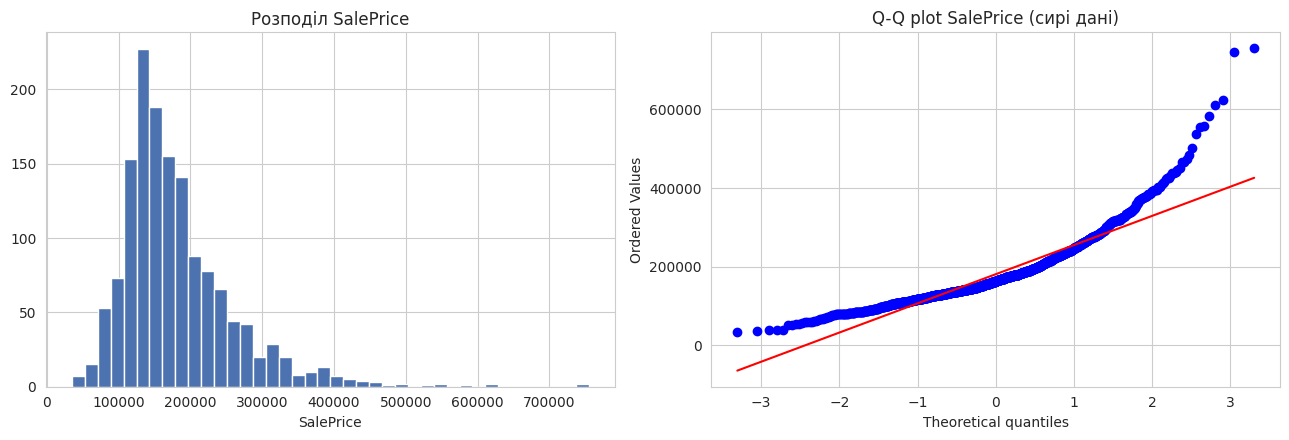

Асиметрія (skewness) SalePrice: 1.883


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].hist(df['SalePrice'], bins=40, color='#4C72B0', edgecolor='white')
axes[0].set_title('Розподіл SalePrice')
axes[0].set_xlabel('SalePrice')

stats.probplot(df['SalePrice'], dist='norm', plot=axes[1])
axes[1].set_title('Q-Q plot SalePrice (сирі дані)')
plt.tight_layout()
plt.show()

print(f"Асиметрія (skewness) SalePrice: {df['SalePrice'].skew():.3f}")

**Висновок EDA щодо цільової змінної:** розподіл `SalePrice` має помітну праву асиметрію (skewness ≈ 1.88) — більшість будинків недорогі, але є "хвіст" дорогих об'єктів. Це важливо тримати в голові при подальшому аналізі залишків (Етап 5): дорогі будинки — рідкісні спостереження, тому модель прогнозуватиме їх з більшою похибкою.

### 1.2. Розбиття вибірки — ДО відбору ознак і будь-якого масштабування

**Питання (методичка): Чому ми повинні розбити дані до, а не після масштабування, кодування або інших операцій, які навчаються на даних? Поясніть термін Data Leakage.**

**Відповідь.** *Data Leakage* ("витік даних") — це ситуація, коли інформація з валідаційної/тестової вибірки, яка в реальному житті ще невідома на момент навчання моделі, тим чи іншим чином "просочується" у процес навчання і впливає на параметри моделі чи на рішення, прийняті під час підготовки даних. Через це якість моделі на Validation/Test виглядає штучно кращою, ніж вона буде на дійсно нових даних.

Якщо порахувати середнє/дисперсію для стандартизації, статистики кореляції для відбору ознак або параметри кодування категорій **на всьому датасеті** (Train + Val + Test одночасно), а вже потім розбити дані — то тестова вибірка неявно "бере участь" у обчисленні цих статистик. Модель отримує непряму інформацію про розподіл тестових даних ще до того, як вона мала б їх "побачити" вперше. Тому правильний порядок дій:

1. Спочатку розбити дані на Train / Validation / Test.
2. Усі статистики, які будь-де використовуються в пайплайні (середнє й std для `StandardScaler`, кореляції для відбору ознак, кодування категорій, медіани для заповнення пропусків тощо) — рахувати **лише на Train**.
3. Отримані параметри (наприклад, `mean`, `std` скейлера) застосовувати до Validation і Test без повторного перенавчання на них.

Саме тому нижче ми розбиваємо дані одразу після первинного структурного огляду — ще до кореляційного аналізу для відбору ознак, кодування категорій і стандартизації.

In [7]:
FEATURES_NUM = ['OverallQual', 'GrLivArea', 'GarageArea', 'TotalBsmtSF', '1stFlrSF',
                'FullBath', 'YearBuilt', 'YearRemodAdd', 'LotArea', 'TotRmsAbvGrd']
FEATURES_CAT_NOMINAL = ['Neighborhood', 'BldgType', 'HouseStyle']
FEATURES_CAT_ORDINAL = ['KitchenQual']
TARGET = 'SalePrice'

data = df[FEATURES_NUM + FEATURES_CAT_NOMINAL + FEATURES_CAT_ORDINAL + [TARGET]].copy()

# 70% Train / 15% Validation / 15% Test
train_df, temp_df = train_test_split(data, test_size=0.30, random_state=RANDOM_STATE)
val_df, test_df = train_test_split(temp_df, test_size=0.50, random_state=RANDOM_STATE)

print(f'Train:      {train_df.shape}')
print(f'Validation: {val_df.shape}')
print(f'Test:       {test_df.shape}')

Train:      (1022, 15)
Validation: (219, 15)
Test:       (219, 15)


### 1.3. Відбір ознак

Статистики нижче (кореляції) обчислені **лише на `train_df`**, як того вимагає методичка.

In [8]:
corr_with_target = train_df[FEATURES_NUM + [TARGET]].corr()[TARGET].sort_values(ascending=False)
print('Кореляція числових ознак з SalePrice (лише Train):')
print(corr_with_target)

Кореляція числових ознак з SalePrice (лише Train):
SalePrice       1.000000
OverallQual     0.784720
GrLivArea       0.689238
GarageArea      0.621937
TotalBsmtSF     0.590017
1stFlrSF        0.583132
FullBath        0.549164
TotRmsAbvGrd    0.519634
YearBuilt       0.512206
YearRemodAdd    0.512190
LotArea         0.262896
Name: SalePrice, dtype: float64


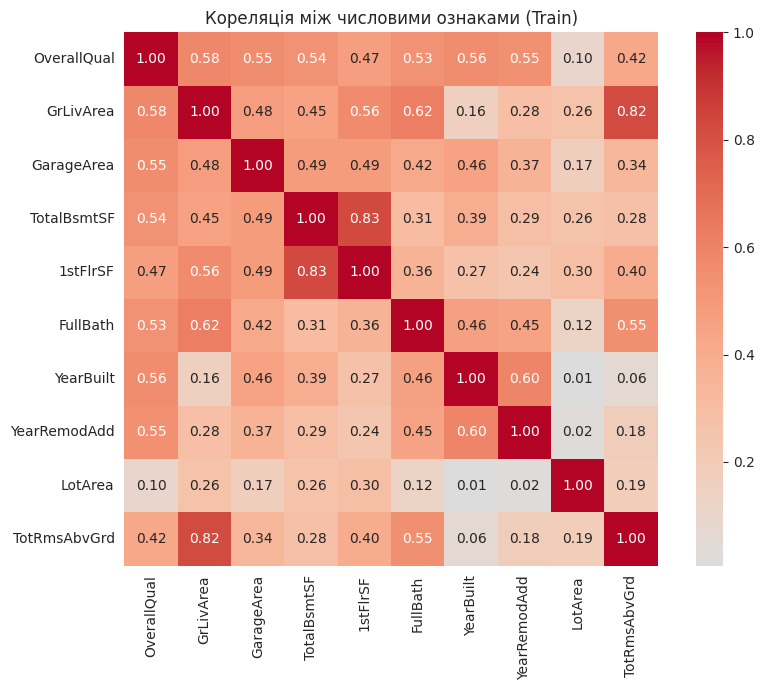

In [9]:
plt.figure(figsize=(9, 7))
corr_matrix = train_df[FEATURES_NUM].corr()
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True)
plt.title('Кореляція між числовими ознаками (Train)')
plt.tight_layout()
plt.show()

**Обґрунтування вибору ознак.**

*Числові:* `OverallQual`, `GrLivArea`, `GarageArea`, `TotalBsmtSF`, `1stFlrSF`, `FullBath`, `YearBuilt`, `YearRemodAdd`, `LotArea`, `TotRmsAbvGrd`. Усі вони мають помітну додатну кореляцію з `SalePrice` на Train (від ~0.26 до ~0.79) і мають зрозумілу економічну логіку впливу на ціну (площа, якість оздоблення, вік будинку, площа гаража/підвалу тощо). Ознаки з екстремально високою часткою пропусків (`LotFrontage`, `GarageYrBlt` тощо) свідомо не включені, щоб не ускладнювати пайплайн імпутацією — завдання явно каже, що *не обов'язково використовувати всі ознаки датасету*.

*Категоріальні:* `Neighborhood`, `BldgType`, `HouseStyle`, `KitchenQual` — саме ті, що прямо названі як приклад у методичці, і всі вони інтуїтивно значущі для ціни (район, тип забудови, поверховість, якість кухні).

*Мультиколінеарність (за матрицею кореляцій вище):* найсильніші пари — `GrLivArea` ↔ `TotRmsAbvGrd` (≈0.83) та `TotalBsmtSF` ↔ `1stFlrSF` (≈0.82). Обидві пари логічні (більша житлова площа → більше кімнат; більша площа першого поверху → зазвичай більший підвал під ним). Ці кореляції не є критичними (< 0.9), але це "кандидати" на мультиколінеарність — повернемось до цього питання з формальною перевіркою через VIF на Етапі 5.

Спеціалізовані методи відбору ознак (SelectKBest, RFE, Lasso тощо) в цьому завданні не застосовувались — обраний ручний відбір на основі кореляції з `SalePrice` та доменної логіки вважається достатнім базовим підходом, як і дозволяє методичка ("щонайменше базовий аналіз кореляцій").

### 1.4. Кодування категоріальних ознак

**Питання (методичка): обґрунтуйте вибір між One-Hot Encoding, Ordinal Encoding чи Target Encoding.**

- `Neighborhood`, `BldgType`, `HouseStyle` — це **номінальні** категорії: між ними немає природного порядку ("район А" не є "більшим" чи "меншим" за "район Б"). Для них використовуємо **One-Hot Encoding**. Ordinal Encoding тут вносив би штучний, нічим не обґрунтований порядок і хибну відстань між категоріями, а Target Encoding (кодування середнім значенням `SalePrice` для категорії) створює високий ризик витоку даних і перенавчання при малій кількості спостережень у деяких категоріях (наприклад, рідкісні `Neighborhood`).
- `KitchenQual` — це **порядкова** категорія (`Po < Fa < TA < Gd < Ex`, тобто "погана → відмінна"). Для неї природно підходить **Ordinal Encoding** з ручним мапінгом, що зберігає реальний порядок якості (0…4), а не One-Hot, який би "загубив" інформацію про впорядкованість.
- Щоб уникнути *dummy variable trap* (лінійної залежності між one-hot стовпцями та вільним членом, що ускладнює, зокрема, обчислення через Normal Equation), для кожної номінальної ознаки видаляємо один рівень-базу (`drop='first'`).

**Питання (методичка): як обробляти категорії, що з'являться на Validation/Test, але яких не було в Train?**

Кодувальник (`OneHotEncoder`) навчається (`fit`) **лише на `train_df`**. Параметр `handle_unknown='ignore'` означає: якщо на Validation/Test зустрінеться категорія, якої не було на Train, — вона кодується вектором нулів по всіх дамі-стовпцях (тобто трактується як "невідома", без помилки виконання). Для порядкової ознаки `KitchenQual` невідоме значення замінюємо на **медіанний ранг якості, обчислений на Train** — це нейтральне, "найбезпечніше" припущення за відсутності іншої інформації.

In [10]:
quality_map = {'Po': 0, 'Fa': 1, 'TA': 2, 'Gd': 3, 'Ex': 4}
train_median_rank = float(np.median(train_df['KitchenQual'].map(quality_map)))
print('Медіанний ранг KitchenQual на Train:', train_median_rank)

def encode_kitchen_qual(series):
    """Ordinal encoding з fallback на медіану Train для невідомих категорій."""
    return series.map(quality_map).fillna(train_median_rank).astype(float)

for d in (train_df, val_df, test_df):
    d['KitchenQual_enc'] = encode_kitchen_qual(d['KitchenQual'])

ohe = OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False)
ohe.fit(train_df[FEATURES_CAT_NOMINAL])  # fit ЛИШЕ на Train
ohe_columns = ohe.get_feature_names_out(FEATURES_CAT_NOMINAL)

def build_feature_matrix(d):
    ohe_part = pd.DataFrame(ohe.transform(d[FEATURES_CAT_NOMINAL]), columns=ohe_columns, index=d.index)
    numeric_part = d[FEATURES_NUM + ['KitchenQual_enc']]
    return pd.concat([numeric_part, ohe_part], axis=1)

X_train_raw = build_feature_matrix(train_df)
X_val_raw = build_feature_matrix(val_df)
X_test_raw = build_feature_matrix(test_df)

y_train = train_df[TARGET].values.astype(float)
y_val = val_df[TARGET].values.astype(float)
y_test = test_df[TARGET].values.astype(float)

print('Кількість фінальних ознак (без bias):', X_train_raw.shape[1])
X_train_raw.head()

Медіанний ранг KitchenQual на Train: 2.0
Кількість фінальних ознак (без bias): 46


,OverallQual,GrLivArea,GarageArea,TotalBsmtSF,1stFlrSF,FullBath,YearBuilt,YearRemodAdd,LotArea,TotRmsAbvGrd,...,BldgType_Duplex,BldgType_Twnhs,BldgType_TwnhsE,HouseStyle_1.5Unf,HouseStyle_1Story,HouseStyle_2.5Fin,HouseStyle_2.5Unf,HouseStyle_2Story,HouseStyle_SFoyer,HouseStyle_SLvl
135,7,1682,530,1304,1682,2,1970,1970,10400,7,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
1452,5,1072,525,547,1072,1,2005,2005,3675,5,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
762,7,1547,614,756,764,2,2009,2009,8640,7,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
932,9,1905,788,1905,1905,2,2006,2006,11670,8,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
435,7,1661,550,799,827,2,1996,1996,10667,6,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0


### 1.5. Масштабування

Стандартизуємо (`StandardScaler`, $z = \dfrac{x-\mu}{\sigma}$) лише **числові** ознаки (у т.ч. закодовану порядкову `KitchenQual_enc`); бінарні one-hot стовпці (0/1) додатково не масштабуються — це стандартна практика. Параметри $\mu, \sigma$ обчислюються **виключно на Train** і застосовуються без перерахунку до Validation/Test.

In [11]:
SCALE_COLS = FEATURES_NUM + ['KitchenQual_enc']

scaler = StandardScaler()
X_train_scaled = X_train_raw.copy()
X_val_scaled = X_val_raw.copy()
X_test_scaled = X_test_raw.copy()

X_train_scaled[SCALE_COLS] = scaler.fit_transform(X_train_raw[SCALE_COLS])   # fit_transform лише на Train
X_val_scaled[SCALE_COLS] = scaler.transform(X_val_raw[SCALE_COLS])           # transform (без fit!)
X_test_scaled[SCALE_COLS] = scaler.transform(X_test_raw[SCALE_COLS])

def add_bias_column(X_df):
    """Додає стовпчик одиниць для вільного члена b і повертає numpy-масив."""
    return np.c_[np.ones(len(X_df)), X_df.values.astype(float)]

X_train_final = add_bias_column(X_train_scaled)
X_val_final = add_bias_column(X_val_scaled)
X_test_final = add_bias_column(X_test_scaled)

print('X_train_final:', X_train_final.shape)
print('X_val_final:  ', X_val_final.shape)
print('X_test_final: ', X_test_final.shape)

X_train_final: (1022, 47)
X_val_final:   (219, 47)
X_test_final:  (219, 47)


## Етап 2. Реалізація лінійної регресії засобами numpy

Модель: $\hat{y} = \mathbf{X}\mathbf{w} + b$ (реалізовано у вигляді єдиного вектора параметрів `w`, де `w[0]` — вільний член `b`, а `X` вже містить стовпчик одиниць — див. `add_bias_column` вище).

Функція втрат — MSE (у формі $\frac{1}{2m}\sum (\hat y - y)^2$, зручній для диференціювання):

$$J(\mathbf{w}) = \frac{1}{2m}\sum_{i=1}^m (\hat y^{(i)} - y^{(i)})^2$$

Градієнт (векторизовано, без циклів `for` по спостереженнях чи ознаках):

$$\nabla_\mathbf{w} J = \frac{1}{m}\mathbf{X}^T(\hat{\mathbf{y}} - \mathbf{y})$$

In [12]:
def predict(X, w):
    """y_hat = X @ w (X вже містить стовпчик одиниць -> w[0] відповідає b)."""
    return X @ w

def compute_cost(X, y, w):
    """MSE-функція втрат (векторизовано, без for-циклів)."""
    m = X.shape[0]
    errors = predict(X, w) - y
    return (1.0 / (2 * m)) * np.sum(errors ** 2)

def compute_gradient(X, y, w):
    """Градієнт MSE за w (векторизовано: матричний добуток замість циклів)."""
    m = X.shape[0]
    errors = predict(X, w) - y
    return (1.0 / m) * (X.T @ errors)

def update_weights(w, gradient, learning_rate):
    """Один крок оновлення параметрів."""
    return w - learning_rate * gradient

### Бонус: Normal Equation (+3 бали)

Розв'язок методом найменших квадратів у замкненій формі отримуємо, прирівнявши градієнт $J(\mathbf{w})$ до нуля:

$$\nabla_\mathbf{w} J = \frac{1}{m}\mathbf{X}^T(\mathbf{X}\mathbf{w}-\mathbf{y}) = 0 \;\Rightarrow\; \mathbf{X}^T\mathbf{X}\mathbf{w} = \mathbf{X}^T\mathbf{y} \;\Rightarrow\; \mathbf{w}^\* = (\mathbf{X}^T\mathbf{X})^{-1}\mathbf{X}^T\mathbf{y}$$

Це не ітеративний, а точний (аналітичний) розв'язок задачі найменших квадратів.

**Обмеження Normal Equation:**
1. **Обчислювальна складність.** Обернення матриці $\mathbf{X}^T\mathbf{X}$ коштує $O(n^3)$, де $n$ — кількість ознак. При великій кількості ознак (тисячі й більше) це стає непрактичним, тоді як градієнтний спуск масштабується лінійно за ознаками.
2. **Необхідність оберненості $\mathbf{X}^T\mathbf{X}$.** Якщо ознаки лінійно залежні (сильна мультиколінеарність або, наприклад, не видалений зайвий рівень one-hot кодування) — матриця вироджена або погано обумовлена, і точний розв'язок нестійкий (у коді нижче використано псевдообернення `pinv`, яке "рятує" від аварійного завершення, але не від нестабільності коефіцієнтів).
3. **Не масштабується на дуже великі вибірки** ($m$ дуже велике) так добре, як мініпакетні методи, і не підтримує онлайн-навчання (дані, що надходять потоково).
4. Не узагальнюється напряму на нелінійні/регуляризовані моделі так природно, як градієнтні методи (хоча для Ridge є аналог із доданим $\lambda I$).

Тому, як і сказано в методичці, реалізацію Normal Equation тут наведено лише як довідковий бонус — основне навчання моделі на наступних етапах виконується виключно градієнтними методами.

In [13]:
XtX = X_train_final.T @ X_train_final
w_normal_eq = np.linalg.pinv(XtX) @ X_train_final.T @ y_train

cost_normal_eq = compute_cost(X_train_final, y_train, w_normal_eq)
print(f'MSE (Normal Equation) на Train: {cost_normal_eq*2:.2f}')
print(f'Це буде нашим орієнтиром "найкращого можливого" MSE для лінійної моделі на цих ознаках.')

MSE (Normal Equation) на Train: 1050073712.86
Це буде нашим орієнтиром "найкращого можливого" MSE для лінійної моделі на цих ознаках.


## Етап 3. Градієнтний спуск: три варіанти оптимізації

Реалізовано три варіанти "з нуля" на `numpy`, усі використовують спільні `compute_cost` / `compute_gradient` з Етапу 2:

1. **Batch GD** — градієнт рахується по всій навчальній вибірці, одне оновлення параметрів за епоху.
2. **SGD** — на кожній епосі дані перемішуються, і параметри оновлюються після кожного окремого прикладу (m оновлень за епоху).
3. **Mini-batch GD** — дані перемішуються і розбиваються на пакети розміру $B=64$; оновлення відбувається після кожного пакету.

Ітерація по прикладах/пакетах (цикл `for`) тут — це **сама суть алгоритмів** SGD і Mini-batch GD (за визначенням вони обробляють дані частинами), а не заборонений спосіб рахувати Cost Function чи градієнт: всередині кожного кроку добуток `X.T @ errors` рахується векторизовано, без циклів по ознаках чи спостереженнях.

In [14]:
def batch_gradient_descent(X, y, learning_rate, epochs):
    w = np.zeros(X.shape[1])
    cost_history = []
    for epoch in range(epochs):
        grad = compute_gradient(X, y, w)
        w = update_weights(w, grad, learning_rate)
        cost_history.append(compute_cost(X, y, w))
    return w, cost_history


def stochastic_gradient_descent(X, y, learning_rate, epochs, random_state=RANDOM_STATE):
    rng = np.random.default_rng(random_state)
    w = np.zeros(X.shape[1])
    m = X.shape[0]
    cost_history = []
    for epoch in range(epochs):
        shuffled_idx = rng.permutation(m)          # перемішування на кожній епосі
        for i in shuffled_idx:                     # по одному прикладу -- визначення SGD
            xi, yi = X[i:i+1], y[i:i+1]
            grad = compute_gradient(xi, yi, w)      # градієнт по 1 прикладу (векторизовано)
            w = update_weights(w, grad, learning_rate)
        cost_history.append(compute_cost(X, y, w))  # повний cost для порівнюваності графіків
    return w, cost_history


def minibatch_gradient_descent(X, y, learning_rate, epochs, batch_size=64, random_state=RANDOM_STATE):
    rng = np.random.default_rng(random_state)
    w = np.zeros(X.shape[1])
    m = X.shape[0]
    cost_history = []
    for epoch in range(epochs):
        shuffled_idx = rng.permutation(m)
        X_shuf, y_shuf = X[shuffled_idx], y[shuffled_idx]
        for start in range(0, m, batch_size):       # по пакетах -- визначення Mini-batch GD
            X_batch = X_shuf[start:start + batch_size]
            y_batch = y_shuf[start:start + batch_size]
            grad = compute_gradient(X_batch, y_batch, w)  # градієнт по пакету (векторизовано)
            w = update_weights(w, grad, learning_rate)
        cost_history.append(compute_cost(X, y, w))
    return w, cost_history

In [15]:
EPOCHS = 150

# Learning rate підібрано експериментально окремо для кожного методу
# (детальніше про чутливість методів до LR -- у висновках нижче)
w_batch, cost_hist_batch = batch_gradient_descent(X_train_final, y_train, learning_rate=0.3, epochs=EPOCHS)
w_sgd, cost_hist_sgd = stochastic_gradient_descent(X_train_final, y_train, learning_rate=0.001, epochs=EPOCHS)
w_mbgd, cost_hist_mbgd = minibatch_gradient_descent(X_train_final, y_train, learning_rate=0.05, epochs=EPOCHS, batch_size=64)

print(f'Batch GD      : фінальний MSE (Train) = {cost_hist_batch[-1]*2:,.0f}')
print(f'SGD           : фінальний MSE (Train) = {cost_hist_sgd[-1]*2:,.0f}')
print(f'Mini-batch GD : фінальний MSE (Train) = {cost_hist_mbgd[-1]*2:,.0f}')
print(f'Normal Eq.    : фінальний MSE (Train) = {cost_normal_eq*2:,.0f}   (орієнтир — точний мінімум)')

Batch GD      : фінальний MSE (Train) = 1,121,082,610
SGD           : фінальний MSE (Train) = 1,097,832,371
Mini-batch GD : фінальний MSE (Train) = 1,098,080,135
Normal Eq.    : фінальний MSE (Train) = 1,050,073,713   (орієнтир — точний мінімум)


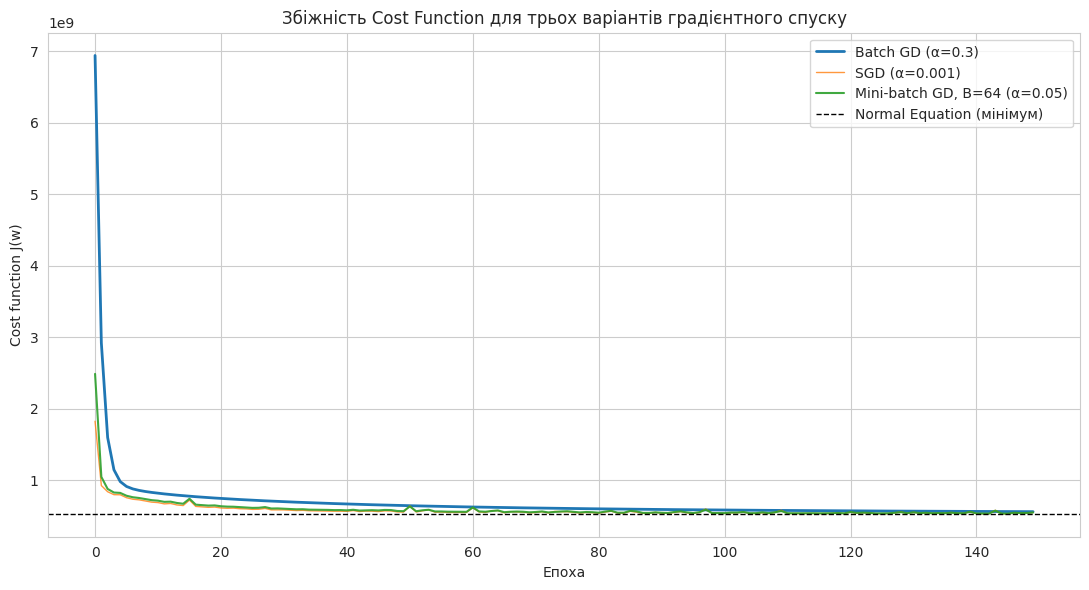

In [16]:
plt.figure(figsize=(11, 6))
plt.plot(cost_hist_batch, label='Batch GD (α=0.3)', linewidth=2)
plt.plot(cost_hist_sgd, label='SGD (α=0.001)', linewidth=1, alpha=0.8)
plt.plot(cost_hist_mbgd, label='Mini-batch GD, B=64 (α=0.05)', linewidth=1.5, alpha=0.9)
plt.axhline(cost_normal_eq, color='black', linestyle='--', linewidth=1, label='Normal Equation (мінімум)')
plt.xlabel('Епоха')
plt.ylabel('Cost function J(w)')
plt.title('Збіжність Cost Function для трьох варіантів градієнтного спуску')
plt.legend()
plt.tight_layout()
plt.show()

**Аналіз поведінки графіків.**

- **Найстабільніше збігається Batch GD** — крива гладка, монотонно спадна, без "тремтіння", тому що градієнт на кожному кроці рахується по всій навчальній вибірці й точно вказує напрямок найшвидшого спуску усередненої по всіх прикладах функції втрат.
- **Найбільші коливання Cost Function — у SGD**: оновлення відбувається за градієнтом, порахованим лише по одному прикладу, який є "шумною" (галасливою) оцінкою справжнього градієнта по всій вибірці. Тому траєкторія має характерне "тремтіння" навіть після виходу на плато.
- **Mini-batch GD — проміжний варіант** за стабільністю: усереднення градієнта по пакету з $B=64$ прикладів значно знижує шум порівняно з SGD (дисперсія оцінки градієнта зменшується приблизно у $B$ разів), але коливання все ще помітніші, ніж у Batch GD.
- **Вплив розміру batch на швидкість/стабільність:** менший batch → більше оновлень параметрів за епоху (тому за той самий *epoch budget* Mini-batch/SGD роблять прогрес швидше "в перерахунку на епоху", ніж Batch GD, який робить лише одне оновлення за епоху), але ціною більшого шуму в оцінці градієнта і потреби у меншому learning rate, щоб цей шум не призводив до розбіжності. Більший batch (аж до Batch GD) — стабільніший, але дорожчий обчислювально на кожному кроці і потребує більше епох, щоб "наздогнати" по кількості реальних оновлень параметрів.
- **Вплив learning rate на збіжність:** методи, що використовують шумну оцінку градієнта (SGD, Mini-batch), потребують **значно менших** α, ніж Batch GD, інакше шум оновлень підсилюється завеликим кроком і алгоритм або розходиться, або "стрибає" навколо мінімуму, не сходячись до нього точно. Це видно і в підібраних тут значеннях: Batch GD стабільно працює з α=0.3, тоді як для SGD довелося взяти α=0.001 (у 300 разів менше) — з великим α SGD миттєво розходиться через шум окремих прикладів.

## Етап 4. Оцінка якості та коефіцієнт детермінації (R²)

$$R^2 = 1 - \frac{\sum_i (y^{(i)}-\hat y^{(i)})^2}{\sum_i (y^{(i)}-\bar y)^2}$$

In [17]:
def r2_score_manual(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    return 1 - ss_res / ss_tot

results = []
for name, w in [('Batch GD', w_batch), ('SGD', w_sgd), ('Mini-batch GD', w_mbgd), ('Normal Equation', w_normal_eq)]:
    r2_train = r2_score_manual(y_train, predict(X_train_final, w))
    r2_val = r2_score_manual(y_val, predict(X_val_final, w))
    r2_test = r2_score_manual(y_test, predict(X_test_final, w))
    results.append({'Метод': name, 'R2_train': r2_train, 'R2_val': r2_val, 'R2_test': r2_test})

results_df = pd.DataFrame(results).set_index('Метод').round(4)
results_df

,R2_train,R2_val,R2_test
Метод,,,
Batch GD,0.8137,0.8815,0.8113
SGD,0.8176,0.8774,0.8372
Mini-batch GD,0.8176,0.8788,0.8351
Normal Equation,0.8255,0.8759,0.8222


**Статистичний зміст R².** R² показує, яку частку дисперсії цільової змінної модель пояснює порівняно з найпростішим "наївним" прогнозом — константою, що дорівнює середньому значенню $\bar y$. $R^2=1$ означає ідеальний прогноз (усі залишки нульові); $R^2=0$ означає, що модель пояснює рівно стільки ж, скільки просте передбачення середнім.

**Чи може R² бути від'ємним? Так.** Формула не гарантує $R^2 \ge 0$: якщо $\sum(y-\hat y)^2 > \sum(y-\bar y)^2$, тобто модель прогнозує **гірше**, ніж проста константа $\bar y$, то R² стає від'ємним. Це трапляється, коли модель дуже погано підібрана (наприклад, невдалі/розбіжні параметри, перенавчання на зовсім інших даних, або застосування моделі до вибірки з іншим розподілом, ніж Train).

**Train vs Test.** У таблиці вище R² на Train і на Test дуже близькі (різниця lише кілька сотих), а Validation навіть дещо вищий за Train і Test для всіх методів. Це означає, що модель **не перенавчена** (немає значного *overfitting*: якби R²(Train) був набагато вищим за R²(Test), це свідчило б про перенавчання — модель "запам'ятала" навчальну вибірку, але погано узагальнює). Помірні абсолютні значення R² (~0.81–0.88) означають, що вибрані 14 ознак пояснюють переважну частину варіації ціни, але не всю — частина дисперсії `SalePrice` пов'язана з ознаками, які ми свідомо не включали в модель (якість оздоблення в деталях, стан даху, розташування щодо доріг тощо).

**Порівняння трьох варіантів GD.** Усі три методи виходять на дуже близькі значення R² (Batch, SGD і Mini-batch відрізняються в межах ~0.02 на Test), що очікувано: усі вони мінімізують ту саму опуклу MSE-функцію втрат для лінійної регресії й наближаються до того самого глобального мінімуму (порівняйте з R² Normal Equation — точного розв'язку). Відмінності між методами — не в *кінцевій якості* моделі (за достатньої кількості епох усі збігаються до одного оптимуму), а в *швидкості й стабільності* збіжності, що ми аналізували на Етапі 3.

## Етап 5. Перевірка статистичних припущень

Діагностику проводимо на основі залишків моделі **Batch GD** на **тестовій вибірці** (Batch GD обрано як найстабільніший і "еталонний" градієнтний метод — Етап 3).

In [18]:
y_pred_test = predict(X_test_final, w_batch)
residuals = y_test - y_pred_test

print(f'Середнє залишків: {residuals.mean():.2f}')
print(f'Std залишків:     {residuals.std():.2f}')

Середнє залишків: 3779.55
Std залишків:     37706.05


### 5.1. Лінійність (Residuals vs Fitted)

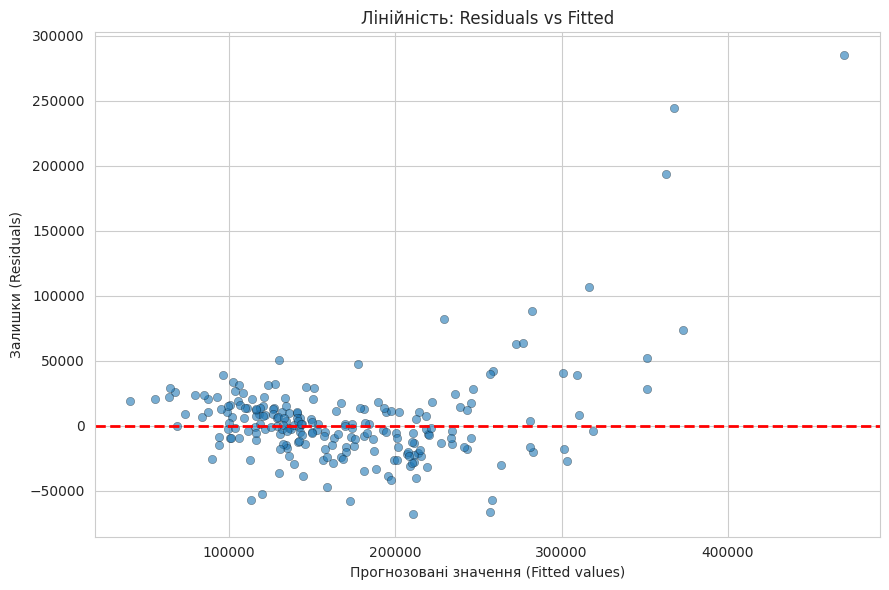

In [19]:
plt.figure(figsize=(9, 6))
plt.scatter(y_pred_test, residuals, alpha=0.6, edgecolor='k', linewidth=0.3)
plt.axhline(0, color='red', linestyle='--', linewidth=2)
plt.xlabel('Прогнозовані значення (Fitted values)')
plt.ylabel('Залишки (Residuals)')
plt.title('Лінійність: Residuals vs Fitted')
plt.tight_layout()
plt.show()

**Висновок.** Припущення лінійності **виконується частково, із застереженням**: для більшості спостережень (недорогі та середні будинки, ліва/центральна частина графіка) залишки розкидані навколо нуля без вираженого систематичного тренду чи кривизни. Проте для об'єктів із найвищими прогнозованими цінами розкид залишків помітно зростає (кілька великих додатних та від'ємних відхилень) — тобто на "хвості" дорогих будинків проста лінійна залежність від обраних ознак працює гірше. Це означає, що для основної маси даних лінійна модель — адекватне наближення, але для сегменту дорогої нерухомості варто розглянути нелінійні ефекти (наприклад, трансформацію `log(SalePrice)`) або додаткові ознаки.

### 5.2. Нормальність залишків (Q-Q plot, гістограма, тест Шапіро-Уілка)

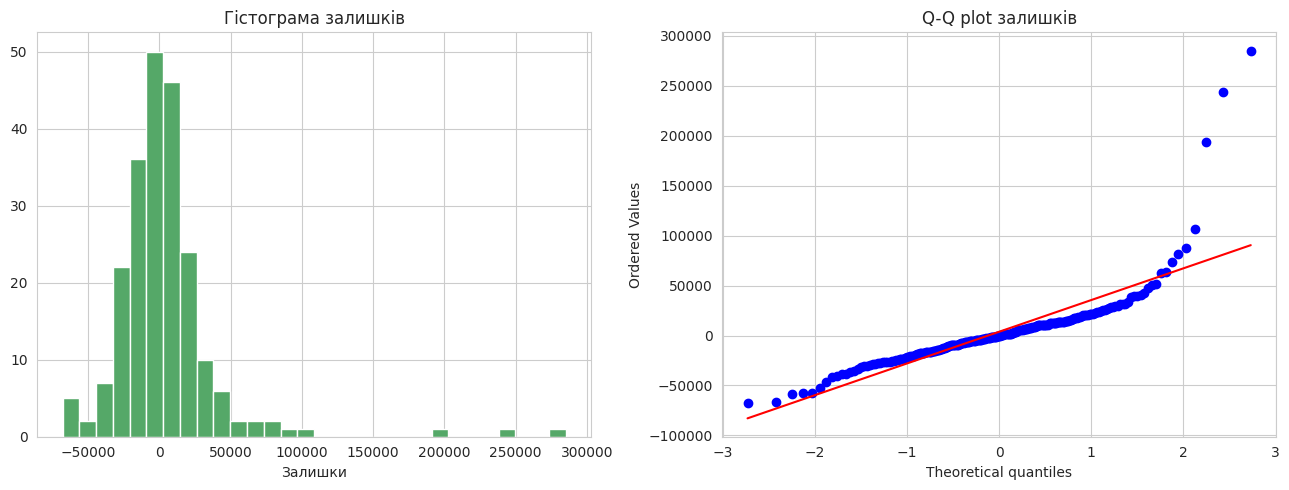

Тест Шапіро-Уілка: statistic=0.7047, p-value=0.000000


In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].hist(residuals, bins=30, color='#55A868', edgecolor='white')
axes[0].set_title('Гістограма залишків')
axes[0].set_xlabel('Залишки')

stats.probplot(residuals, dist='norm', plot=axes[1])
axes[1].set_title('Q-Q plot залишків')

plt.tight_layout()
plt.show()

shapiro_stat, shapiro_p = stats.shapiro(residuals)
print(f'Тест Шапіро-Уілка: statistic={shapiro_stat:.4f}, p-value={shapiro_p:.6f}')

**Висновок.** Припущення нормальності залишків **порушується**, тому що: (1) тест Шапіро-Уілка дає p-value $\ll 0.05$ — гіпотеза про нормальність відхиляється; (2) на Q-Q plot точки помітно відхиляються від прямої лінії саме на "хвостах" розподілу (важкі хвости), а гістограма залишків має видиму додатну асиметрію з кількома великими викидами праворуч. Це узгоджується з асиметрією самої цільової змінної `SalePrice`, яку ми відзначили на Етапі 1 (skewness ≈ 1.88): рідкісні дуже дорогі будинки дають непропорційно великі залишки. Це означає, що довірчі інтервали й статистичні тести для коефіцієнтів моделі (які спираються на припущення нормальності похибок), строго кажучи, не зовсім коректні — хоча самі точкові оцінки коефіцієнтів методом найменших квадратів залишаються незміщеними. На практиці це типова проблема для цін на нерухомість і часто вирішується логарифмуванням цільової змінної.

### 5.3. Гомоскедастичність (Scale-Location plot)

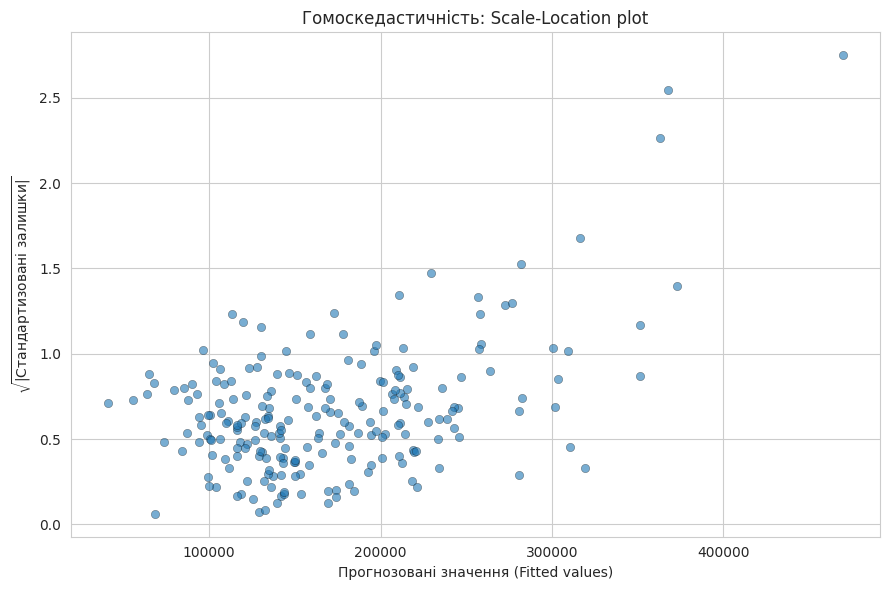

низькі ціни   : std(залишків) = 18,735
середні ціни  : std(залишків) = 17,555
високі ціни   : std(залишків) = 59,009


In [21]:
standardized_residuals = residuals / residuals.std()
sqrt_abs_std_resid = np.sqrt(np.abs(standardized_residuals))

plt.figure(figsize=(9, 6))
plt.scatter(y_pred_test, sqrt_abs_std_resid, alpha=0.6, edgecolor='k', linewidth=0.3)
plt.xlabel('Прогнозовані значення (Fitted values)')
plt.ylabel(r'$\sqrt{|\mathrm{Стандартизовані\ залишки}|}$')
plt.title('Гомоскедастичність: Scale-Location plot')
plt.tight_layout()
plt.show()

# Кількісна перевірка: як змінюється std залишків у групах за рівнем fitted value
order = np.argsort(y_pred_test)
n = len(order)
tercile_names = ['низькі ціни', 'середні ціни', 'високі ціни']
for i, name in enumerate(tercile_names):
    idx = order[i * n // 3:(i + 1) * n // 3]
    print(f'{name:14s}: std(залишків) = {residuals[idx].std():,.0f}')

**Висновок.** Припущення гомоскедастичності **порушується**, тому що на Scale-Location графіку розкид (і чисельно — стандартне відхилення залишків по терцилях прогнозованих значень) явно зростає у групі найдорожчих будинків: дисперсія помилок там у кілька разів більша, ніж для дешевих/середніх об'єктів (класична "лійкоподібна" форма). Це означає, що похибка прогнозу моделі не є однорідною по всьому діапазону цін: для дорогих будинків модель не лише має гірше в середньому передбачення, а й значно менш **передбачувану** похибку. Практичний наслідок — стандартні похибки коефіцієнтів, отримані у припущенні гомоскедастичності, применшують невизначеність для дорогого сегмента ринку; для строгого статистичного висновку варто було б використовувати робастні (heteroscedasticity-consistent) стандартні похибки або трансформацію цільової змінної.

### 5.4. Відсутність мультиколінеарності (кореляційна матриця + VIF)

In [22]:
vif_cols = FEATURES_NUM + ['KitchenQual_enc']
X_vif = np.c_[np.ones(len(X_train_scaled)), X_train_scaled[vif_cols].values]

vif_data = pd.DataFrame({
    'Ознака': vif_cols,
    'VIF': [variance_inflation_factor(X_vif, i) for i in range(1, X_vif.shape[1])]
}).sort_values('VIF', ascending=False)

vif_data

,Ознака,VIF
1,GrLivArea,5.068083
4,1stFlrSF,3.809198
3,TotalBsmtSF,3.806572
9,TotRmsAbvGrd,3.321885
0,OverallQual,2.944433
10,KitchenQual_enc,2.387776
6,YearBuilt,2.364201
5,FullBath,2.213838
7,YearRemodAdd,2.081444
2,GarageArea,1.793068


**Висновок.** Припущення про відсутність мультиколінеарності **в цілому виконується, з одним прикордонним випадком**: усі VIF, окрім `GrLivArea`, помітно нижчі за консервативний поріг 5 (більшість — в діапазоні 1.1–3.8). Найвище значення — у `GrLivArea` (VIF ≈ 5.1, прикордонне значення навколо порогу 5), що узгоджується з виявленою на Етапі 1 кореляцією `GrLivArea` ↔ `TotRmsAbvGrd` (≈0.83). Це означає, що загалом ознаки достатньо незалежні одна від одної, щоб коефіцієнти моделі можна було інтерпретувати змістовно (кожен коефіцієнт відображає переважно "власний" внесок ознаки), але для пари `GrLivArea`/`TotRmsAbvGrd` частина їхнього спільного впливу на ціну "розмазується" між двома коефіцієнтами, тому конкретне числове значення ваги при кожній з них окремо варто інтерпретувати з обережністю.

**Чи вплинула мультиколінеарність на стабільність/інтерпретацію коефіцієнтів?** Оскільки жоден VIF не перевищує критичний поріг 5 суттєво (немає VIF в діапазоні 10+, який би вказував на серйозну проблему), мультиколінеарність тут **не є критичною** і не спотворює якість прогнозу моделі (R² на Test залишається стабільним і близьким до R² на Train — Етап 4). Проте помірна кореляція `GrLivArea`/`TotRmsAbvGrd` та `TotalBsmtSF`/`1stFlrSF` означає, що *окремі* коефіцієнти цих ознак є дещо менш стійкими (чутливими до конкретної навчальної вибірки) і їх не варто інтерпретувати ізольовано одне від одного — коректніше говорити про їхній сукупний внесок, ніж про внесок кожної ознаки окремо. Через помірний (не критичний) рівень мультиколінеарності Ridge-регуляризація (Експеримент В Етапу 6) у цьому випадку не є обов'язковою, хоча могла б додатково стабілізувати саме ці два коефіцієнти.

## Етап 6. Завдання для глибокого розуміння — Експеримент А (вплив масштабування)

Порівнюємо Mini-batch GD (B=64) на тих самих ознаках і тому самому Train/Val/Test розбитті **без стандартизації** (сирі значення ознак) і **зі стандартизацією**, підбираючи прийнятний learning rate для кожного випадку.

In [23]:
X_train_unscaled = add_bias_column(X_train_raw)   # ті самі ознаки, БЕЗ StandardScaler

print('Діапазони "сирих" числових ознак (Train):')
print(X_train_raw[FEATURES_NUM].agg(['min', 'max']).T)

Діапазони "сирих" числових ознак (Train):
               min     max
OverallQual      1      10
GrLivArea      334    5642
GarageArea       0    1418
TotalBsmtSF      0    6110
1stFlrSF       334    4692
FullBath         0       3
YearBuilt     1872    2010
YearRemodAdd  1950    2010
LotArea       1300  215245
TotRmsAbvGrd     2      14


Ознаки мають кардинально різні масштаби: `OverallQual` у діапазоні 1–10, а `LotArea` — до ~200 000+. Спробуємо звичний для стандартизованих даних learning rate (α=0.05, як для Mini-batch GD зі стандартизацією):

In [24]:
_, cost_hist_unscaled_same_lr = minibatch_gradient_descent(
    X_train_unscaled, y_train, learning_rate=0.05, epochs=10, batch_size=64
)
print('Cost по епохах (α=0.05, без масштабування):')
print([f'{c:.3e}' for c in cost_hist_unscaled_same_lr])

Cost по епохах (α=0.05, без масштабування):
['1.021e+234', 'inf', 'nan', 'nan', 'nan', 'nan', 'nan', 'nan', 'nan', 'nan']


/tmp/ipykernel_2141/3405854420.py:9: RuntimeWarning: overflow encountered in square
  return (1.0 / (2 * m)) * np.sum(errors ** 2)
/tmp/ipykernel_2141/3405854420.py:15: RuntimeWarning: overflow encountered in matmul
  return (1.0 / m) * (X.T @ errors)
/tmp/ipykernel_2141/3405854420.py:3: RuntimeWarning: invalid value encountered in matmul
  return X @ w
/tmp/ipykernel_2141/3405854420.py:15: RuntimeWarning: invalid value encountered in matmul
  return (1.0 / m) * (X.T @ errors)


Як і очікувалось, з тим самим α, що чудово працює на стандартизованих даних, алгоритм на несмаштабованих ознаках миттєво **розходиться** (Cost вибухає до нескінченності/NaN вже за кілька епох) — великі за модулем ознаки (`LotArea`, `GrLivArea` тощо) дають величезні за модулем градієнти, і крок α=0.05 стає для них надмірним. Підберемо набагато менший, стабільний α для несмаштабованого варіанту:

In [25]:
LR_UNSCALED = 2e-9
LR_SCALED = 0.05
EPOCHS_EXPERIMENT = 300

w_unscaled, cost_hist_unscaled = minibatch_gradient_descent(
    X_train_unscaled, y_train, learning_rate=LR_UNSCALED, epochs=EPOCHS_EXPERIMENT, batch_size=64
)
w_scaled_exp, cost_hist_scaled = minibatch_gradient_descent(
    X_train_final, y_train, learning_rate=LR_SCALED, epochs=EPOCHS_EXPERIMENT, batch_size=64
)

print(f'Без масштабування (α={LR_UNSCALED:.0e}), Cost після {EPOCHS_EXPERIMENT} епох: {cost_hist_unscaled[-1]:,.0f}')
print(f'Зі масштабуванням  (α={LR_SCALED}),  Cost після {EPOCHS_EXPERIMENT} епох: {cost_hist_scaled[-1]:,.0f}')

Без масштабування (α=2e-09), Cost після 300 епох: 1,381,618,091
Зі масштабуванням  (α=0.05),  Cost після 300 епох: 564,038,238


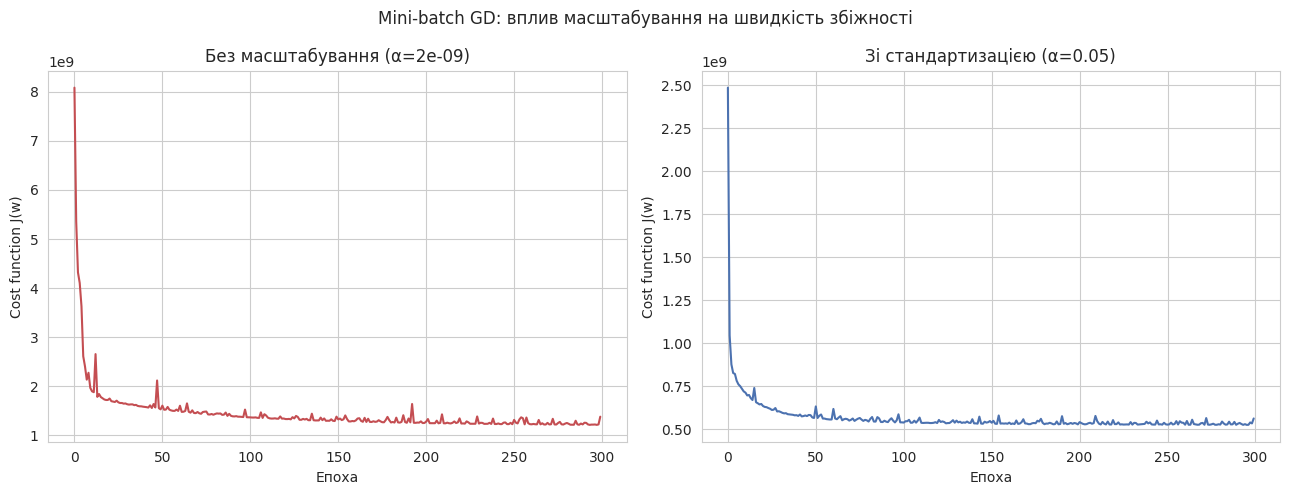

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(cost_hist_unscaled, color='#C44E52')
axes[0].set_title(f'Без масштабування (α={LR_UNSCALED:.0e})')
axes[0].set_xlabel('Епоха')
axes[0].set_ylabel('Cost function J(w)')

axes[1].plot(cost_hist_scaled, color='#4C72B0')
axes[1].set_title(f'Зі стандартизацією (α={LR_SCALED})')
axes[1].set_xlabel('Епоха')
axes[1].set_ylabel('Cost function J(w)')

plt.suptitle('Mini-batch GD: вплив масштабування на швидкість збіжності')
plt.tight_layout()
plt.show()

**Порівняння швидкості збіжності.** Зі стандартизацією Mini-batch GD виходить на плато вже за перші ~20-30 епох, з фінальним Cost, дуже близьким до оптимуму. Без стандартизації, навіть з learning rate, зменшеним у **25 мільйонів разів** (2·10⁻⁹ проти 0.05) лише щоб алгоритм не розходився, Cost після 300 епох залишається на порядки вищим — модель просувається до мінімуму надзвичайно повільно.

**Геометричне пояснення.** Функція втрат $J(\mathbf{w})$ для лінійної регресії — квадратична (параболоїд), і форма її ліній рівня визначається масштабами ознак. Якщо ознаки мають дуже різні дисперсії (наприклад, `LotArea` з розкидом у десятки тисяч проти `OverallQual` з розкидом 1–10), лінії рівня Cost function перетворюються на дуже витягнутий еліпс: уздовж "осі" ознаки з великою дисперсією поверхня дуже стрімка (навіть невеликий крок по цій координаті різко змінює Cost), а вздовж "осі" ознаки з малою дисперсією — майже плоска. Градієнтний спуск рухається перпендикулярно до ліній рівня, тому на витягнутому еліпсі він змушений робити зигзагоподібні кроки: єдиний learning rate, достатньо малий, щоб не "перестрибнути" через дно вздовж стрімкого напрямку, виявляється катастрофічно малим для ефективного руху вздовж пологого напрямку. У результаті збіжність стає дуже повільною. Стандартизація (яка робить дисперсію кожної ознаки рівною 1) перетворює витягнутий еліпс на майже коло — градієнт тоді вказує майже прямо на мінімум, і один і той самий, помірний learning rate однаково добре працює по всіх напрямках, тому збіжність відбувається значно швидше і стабільніше.

## Підсумок

- Обрано рекомендований датасет **Ames Housing / Kaggle House Prices** з цільовою змінною `SalePrice`, 10 числовими та 4 категоріальними ознаками, обґрунтованими кореляцією з ціною та доменною логікою.
- Дані розбито на Train/Validation/Test **до** будь-яких операцій, що навчаються на даних (пояснено поняття Data Leakage); кодування категорій (One-Hot для номінальних, Ordinal — для `KitchenQual`) та стандартизація підібрані/навчені виключно на Train.
- Лінійну регресію та всі три варіанти градієнтного спуску (Batch, SGD, Mini-batch) реалізовано "з нуля" на `numpy`, без циклів у обчисленні Cost Function/градієнта; додатково наведено Normal Equation як точний орієнтир (бонус).
- Усі три методи GD сходяться до близької якості (R² ≈ 0.81–0.88 на Train/Val/Test, ознак перенавчання не виявлено), відрізняючись стабільністю та швидкістю збіжності: Batch GD — найстабільніший, SGD — найшумніший, Mini-batch — компроміс.
- Перевірка статистичних припущень на залишках показала: лінійність — здебільшого виконується (з відхиленням на дорогих об'єктах); нормальність і гомоскедастичність — **порушуються** через праву асиметрію `SalePrice`; мультиколінеарність — не критична (VIF < 5.2 для всіх ознак).
- Експеримент А підтвердив і теоретично, і практично: без масштабування ознак градієнтний спуск працює на порядки повільніше й вимагає екстремально малого learning rate через витягнуту форму поверхні Cost Function.
